In [ ]:
# cumc


from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
from femr.models.tokenizer.clmbr_tokenizer import CLMBRTokenizer
import pickle as pl
from pathlib import Path

# cumc_lab_codes = ["LOINC/26515-7//UCUM/10*9/L","LOINC/2160-0//UCUM/mg/dL",\
# "LOINC/1968-7//UCUM/mg/dL","LOINC/2708-6//UCUM/%"]

# mimic_lab_code = {
#     "glucose": ["LAB//50931//mg/dL"],    
#     "pao2":       ["LAB//50821//mm Hg"],
#     "platelets": ["LAB//51265//K/uL"],
#     "creatinine": ["LAB//50912//mg/dL"]
# }

# tpp_task_path =
# ntp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/ntp/ntp_task.pkl"
# tpp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/tpp/tpp_task.pkl"
# best_159744

# mtpp_task_path = "/user/zj2398/cache/mtpp_8k_T_8_V_5/mtpp_task.pkl"
# mtpp_task_path = "/data2/processed_datasets/zj2398/femr/mimic/mtpp_T_16_V_10/mtpp_task.pkl"
# mimic_ontology_path = "/data2/processed_datasets/zj2398/femr/mimic/mtpp_T_8_V_5/ontology.pkl"

def check_code(base_dir,model_name, lab_codes,ontology_path,model_task_path):
    with open(model_task_path,"rb") as f:
        model_task = pl.load(f)
    with open(ontology_path, 'rb') as f:
        ontology = pl.load(f)
    tokenizer_path =base_dir/"tokenizer"
    if model_name != "ntp":
        tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
        tokenizer_vocab = [ i["code_string"] for i in tokenizer.dictionary["vocab"] if i["type"] == "code"]
    else:
        tokenizer = CLMBRTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
        tokenizer_vocab = [ i["code_string"] for i in tokenizer.dictionary["vocab"] if i["type"] == "code"]
        pretraining_task = list(tokenizer.original_code_to_id.keys())
    print(len(tokenizer_vocab),tokenizer_vocab)
    for code in lab_codes:
        if code in tokenizer_vocab:
            print(f"code {code} in {model_name} tokenizer")
        if model_name == "mtpp":
            if (code in model_task.task_to_index_map.keys() or code in model_task.numerical_task_to_index_map.keys()):
                print(f"code {code} in pretraining task of {model_name}")
        elif model_name == "ntp":
            if code in pretraining_task:
                print(f"code {code} in pretraining task of {model_name}")
        else:
            if code in model_task.task_to_index_map.keys():
                print(f"code {code} in pretraining task of {model_name}")
    print()



# for model in ["tpp","mtpp"]:
# mimic_base_dir = Path("/data2/processed_datasets/zj2398/femr/mimic/mtpp_T_8_V_5")
# check_code(mimic_base_dir,"mtpp",mimic_lab_code,mimic_ontology_path,mtpp_task_path)

mtpp_task_path = "/data2/processed_datasets/zj2398/femr/mimic/mtpp_T_8_V_5/mtpp_task.pkl"
with open(mtpp_task_path,"rb") as f:
    mtpp_task = pl.load(f)
full_codes = set(mtpp_task.numerical_task_to_index_map.keys())

mtpp_value_task_path = "/data2/processed_datasets/zj2398/femr/mimic/mtpp_value_T_8_V_5/mtpp_value_task.pkl"
with open(mtpp_value_task_path,"rb") as f:
    mtpp_value_task = pl.load(f)
new_codes = set(mtpp_value_task.pretraining_task_codes)
print(len(full_codes),len(new_codes))
print(full_codes-new_codes)
print(new_codes-full_codes)

ontology_path = "/data2/processed_datasets/zj2398/femr/mimic/mtpp_T_8_V_5/ontology.pkl"
with open(ontology_path, 'rb') as f:
    ontology = pl.load(f)
def check_tokenizer(tokenizer_path):
    tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
    tokenizer_vocab = [ i["code_string"] for i in tokenizer.dictionary["vocab"] if i["type"] == "code"]
    return tokenizer_vocab
full_tokenizer = check_tokenizer("/data2/processed_datasets/zj2398/femr/mimic/mtpp_T_8_V_5/tokenizer")
new_tokenizer = check_tokenizer("/data2/processed_datasets/zj2398/femr/mimic/mtpp_value_T_8_V_5/tokenizer")


# numerical_code = list(model_task.numerical_task_to_index_map.keys())
# nonnumerical_code = list(model_task.task_to_index_map.keys())
# print(len(numerical_code),numerical_code)
# print(len(nonnumerical_code),nonnumerical_code)
# check_code(cumc_base_dir,"tpp",cumc_lab_codes,cumc_ontology_path,tpp_task_path)
# check_code(cumc_base_dir,"ntp",cumc_lab_codes,cumc_ontology_path,ntp_task_path)

# print(len(mtpp_tokenizer.dictionary["vocab"]))
# print(mtpp_task.numerical_time_bins.shape)
# # print(mtpp_task.non_numerical_time_bins.shape)
# print(len(motor_task.pretraining_task_info))
# # print(tpp_task.time_bins.shape)




1164 1156
{'LAB//51507//#/lpf', 'LAB//51664//UNK', 'LAB//51252//N/A', 'LAB//52171//N/A', 'INFUSION_START//227689', 'LAB//51489//#/hpf', 'LAB//50986//ng/mL', 'LAB//51233//N/A'}
set()


In [21]:
from femr.models.architecture.embedding import FEMRModel
print(tokenizer.vocab_size)
model_config = FEMRModel.config_class.from_pretrained(model_path)
model = FEMRModel(model_config,task_config = task.get_task_config(),loss_type="mtpp_shared")
print(model.backbone.embed_bag)

12679
the hidden size is 768
create loss type is mtpp_shared
EmbeddingBag(12604, 768, mode='sum')


In [ ]:
# check mimic
import pandas as pd
import pickle as pl
ntp_task_path = "/user/zj2398/cache/ntp/ntp_task.pkl"
mtpp_task_path = "/user/zj2398/cache/mtpp_8k_T_8_V_5/mtpp_task.pkl"
tpp_task_path = "/user/zj2398/cache/tpp/tpp_task.pkl"
new_mtpp_task_path = "/user/zj2398/cache/mtpp_8k_T_8_V_5_all_nonnume/mtpp_task.pkl"
with open(tpp_task_path , 'rb') as f:
    tpp_task = pl.load(f)
with open(ntp_task_path , 'rb') as f:
    ntp_task = pl.load(f)
with open(mtpp_task_path , 'rb') as f:
    mtpp_task = pl.load(f)
with open(new_mtpp_task_path , 'rb') as f:
    new_mtpp_task = pl.load(f)
print(ntp_task.clmbr_vocab_size)
print(len(mtpp_task.numerical_task_to_index_map))
print(len(mtpp_task.task_to_index_map))
print(len(tpp_task.task_to_index_map))
print(len(new_mtpp_task.numerical_task_to_index_map))
print(len(new_mtpp_task.task_to_index_map))

/user/zj2398/.conda/envs/tte/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


8390
1164
4936
6100
1164
5882


In [8]:
# check cumc
import pandas as pd
import pickle as pl
ntp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/ntp/ntp_task.pkl"
mtpp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/mtpp/mtpp_task.pkl"
tpp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/tpp/tpp_task.pkl"
motor_task_path = "/data2/processed_datasets/zj2398/femr/cumc/motor/motor_task.pkl"
# new_mtpp_task_path = "/user/zj2398/cache/mtpp_8k_T_8_V_5_all_nonnume/mtpp_task.pkl"
with open(tpp_task_path , 'rb') as f:
    tpp_task = pl.load(f)
with open(ntp_task_path , 'rb') as f:
    ntp_task = pl.load(f)
with open(mtpp_task_path , 'rb') as f:
    mtpp_task = pl.load(f)
with open(motor_task_path , 'rb') as f:
    motor_task = pl.load(f)
# with open(new_mtpp_task_path , 'rb') as f:
#     new_mtpp_task = pl.load(f)
print(ntp_task.clmbr_vocab_size)
print(len(mtpp_task.numerical_task_to_index_map))
print(len(mtpp_task.task_to_index_map))
print(mtpp_task.num_value_bins)
print(mtpp_task.non_numerical_time_bins.shape)
print(len(tpp_task.task_to_index_map))
print(len(motor_task.task_to_index_map))
# print(len(new_mtpp_task.numerical_task_to_index_map))
# print(len(new_mtpp_task.task_to_index_map))

2336
716
6256
10
(6256, 9)
6972
6972


In [1]:
# base_dir = Path("/data2/processed_datasets/zj2398/femr/mimic/deephit_tpp")
# model_path = base_dir/"transformer/best_221573"
# tokenizer_path = base_dir/"tokenizer"
# ontology_path =  base_dir/"ontology.pkl"
# task_path = base_dir/"tpp_task.pkl"

from femr.models.architecture.embedding import FEMRModel
from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
from femr.models.tokenizer.clmbr_tokenizer import CLMBRTokenizer
import pickle as pl
from pathlib import Path

def check_vocab(model_path,tokenizer_path,ontology_path,task_path,task_name):
    with open(task_path, 'rb') as f:
        task = pl.load(f)
    with open(ontology_path, 'rb') as f:
        ontology = pl.load(f)
    tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
    print(tokenizer.vocab_size)
    tokenizer2 = HierarchicalTokenizer.from_pretrained(model_path, ontology=ontology)
    print(tokenizer2.vocab_size)
    model_config = FEMRModel.config_class.from_pretrained(model_path)
    model = FEMRModel(model_config,task_config = task.get_task_config(),loss_type=task_name)
    print(model.backbone.embed_bag)

# # tpp
# tpp_dir = Path("/data2/processed_datasets/zj2398/femr/mimic/deephit_tpp")
# tpp_model_path = tpp_dir/"transformer/best_221573"
# tpp_tokenizer_path = tpp_dir/"tokenizer"
# tpp_ontology_path =  tpp_dir/"ontology.pkl"
# tpp_task_path = tpp_dir/"tpp_task.pkl"

# check_vocab(tpp_model_path,tpp_tokenizer_path,tpp_ontology_path,tpp_task_path,"tpp")

# # mtpp
# mtpp_dir = Path("/data2/processed_datasets/zj2398/femr/mimic/mtpp_T_16_V_10")
# mtpp_model_path = mtpp_dir/"transformer/best-147565"
# mtpp_tokenizer_path = mtpp_dir/"tokenizer"
# mtpp_ontology_path =  mtpp_dir/"ontology.pkl"
# mtpp_task_path = mtpp_dir/"mtpp_task.pkl"

# check_vocab(mtpp_model_path,mtpp_tokenizer_path,mtpp_ontology_path,mtpp_task_path,"mtpp_shared")

# # motor

motor_dir = Path("/data/models/zj2398/femr/mimic_motor_8k/")
motor_model_path = motor_dir/"output/best_100620"
motor_tokenizer_path = motor_dir/"tokenizer"
motor_ontology_path = motor_dir/"ontology.pkl"
motor_task_path = motor_dir/"motor_task.pkl"
check_vocab(motor_model_path,motor_tokenizer_path,motor_ontology_path,motor_task_path,"motor")

/data/anaconda3/envs/motor_chao/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


12683
12681
the hidden size is 768
create loss type is motor
EmbeddingBag(12681, 768, mode='sum')


In [2]:
mtpp_dir = Path("/data2/processed_datasets/zj2398/femr/mimic/mtpp_T_8_V_5")
mtpp_model_path = mtpp_dir/"transformer/best_159744"
mtpp_tokenizer_path = mtpp_dir/"tokenizer"
mtpp_ontology_path =  mtpp_dir/"ontology.pkl"
mtpp_task_path = mtpp_dir/"mtpp_task.pkl"

check_vocab(mtpp_model_path,mtpp_tokenizer_path,mtpp_ontology_path,mtpp_task_path,"mtpp_shared")

12679
12604
the hidden size is 768
create loss type is mtpp_shared
EmbeddingBag(12604, 768, mode='sum')


In [6]:
print(len(model_task.numerical_task_to_index_map.keys()))
key_list = list(model_task.numerical_task_to_index_map.keys())
# print(key_list)
# Bilirubin
# if "LAB//50885//mg/dL" in key_list:
#     print("yes")
# for key in model_task.numerical_task_to_index_map.keys():
#     if key == "LAB//50885//mg/dL":
#         print(key)
print(model_task.numerical_task_to_index_map)
# print(model_task.numerical_task_to_index_map["LAB//50885//mg/dL"])
# numerical_lab_codes = list(model_task.numerical_task_to_index_map.keys())
# for i in range(len(model_task.numerical_task_to_index_map.keys())):
#     if model_task.numerical_time_bins[i][6]/3600 <=10:
#         print(numerical_lab_codes[i],model_task.numerical_time_bins[i]/60)

numerical_lab_codes = list(model_task.task_to_index_map.keys())
for i in range(len(numerical_lab_codes)):
    if model_task.non_numerical_time_bins[i][1]/3600 >= 24 and "DIAGNOSIS//ICD//10//E1" in numerical_lab_codes[i]:
        print(numerical_lab_codes[i],model_task.non_numerical_time_bins[i]/(3600*24*30))

# bilirubin_time_interval = model_task.numerical_time_bins[3]
# print(bilirubin_time_interval/3600)

# print((bilirubin_time_interval[1:]-bilirubin_time_interval[:-1])/3600)
# for idx in range(1, len(bilirubin_time_interval)):
#     print(bilirubin_time_interval[idx] - bilirubin_time_interval[idx-1])
# print(model_task.value_bins[3])

1164
{'LAB//51516//#/hpf': 0, 'LAB//51476//#/hpf': 1, 'LAB//51493//#/hpf': 2, 'LAB//50885//mg/dL': 3, 'LAB//51249//g/dL': 4, 'LAB//52172//fL': 5, 'LAB//50863//IU/L': 6, 'LAB//51275//sec': 7, 'LAB//51249//%': 8, 'LAB//51274//sec': 9, 'LAB//51237//UNK': 10, 'LAB//50862//g/dL': 11, 'LAB//50878//IU/L': 12, 'LAB//50970//mg/dL': 13, 'LAB//52075//K/uL': 14, 'LAB//52073//K/uL': 15, 'LAB//52069//K/uL': 16, 'LAB//52074//K/uL': 17, 'LAB//51133//K/uL': 18, 'LAB//51087//UNK': 19, 'LAB//50861//IU/L': 20, 'LAB//50960//mg/dL': 21, 'LAB//50947//UNK': 22, 'LAB//51678//UNK': 23, 'LAB//50934//UNK': 24, 'LAB//52135//%': 25, 'LAB//50893//mg/dL': 26, 'LAB//51498// ': 27, 'LAB//51492//mg/dL': 28, 'LAB//51484//mg/dL': 29, 'LAB//51478//mg/dL': 30, 'LAB//51514//mg/dL': 31, 'LAB//51491//units': 32, 'LAB//50813//mmol/L': 33, 'LAB//51463//UNK': 34, 'LAB//50993//uIU/mL': 35, 'LAB//50956//IU/L': 36, 'LAB//51000//mg/dL': 37, 'LAB//50907//mg/dL': 38, 'LAB//50904//mg/dL': 39, 'LAB//50903//Ratio': 40, 'LAB//50905//mg/dL'

In [2]:
print(len(mtpp_task.pretraining_task_info))

6100


In [13]:
for code in lab_regression_codes:  
    if code in list(tpp_task.task_to_index_map.keys()):
        print(code,tpp_task.task_to_index_map[code])
    # if code in list(mtpp_task.numerical_task_to_index_map.keys()):
    #     print(code,mtpp_task.numerical_task_to_index_map[code])
    # if code in list(mtpp_task.task_to_index_map.keys()):
    #     print(code,mtpp_task.task_to_index_map[code])

LOINC/26515-7//UCUM/10*9/L 47
LOINC/2160-0//UCUM/mg/dL 27
LOINC/1968-7//UCUM/mg/dL 61
LOINC/2708-6//UCUM/% 58


In [2]:
import pickle as pl
import json
# mtpp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/mtpp/mtpp_task.pkl"
# tpp_task_path = "/data2/processed_datasets/zj2398/femr/cumc/tpp/tpp_task.pkl"
# motor_json_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/models/femr/motor_large_no_visit_id/motor_model/config.json"
# with open(tpp_task_path,"rb") as f:
#     tpp_task = pl.load(f)
# with open(mtpp_task_path,"rb") as f:
#     mtpp_task = pl.load(f)
# with open (motor_json_path,"r") as file:
#     motor_json = json.load(file)
# print(len(motor_json["task_config"]["task_kwargs"]["pretraining_task_info"]))
# print(len(tpp_task.pretraining_task_info))

mtpp_task_path = "/user/zj2398/cache/mtpp_8k_T_16_V_5/mtpp_task.pkl"
# mtpp_task_path = "/user/zj2398/cache/mtpp_8k_num_bin5/mtpp_task.pkl"
# mtpp_task_path = "/shared/share_mala/zj2398/models/mtpp_8k/mtpp_all_shared_6100_bin_5/mtpp_task.pkl"
# tpp_task_path = "/shared/share_mala/zj2398/models/tpp_8k/tpp_task.pkl"
# motor_task_path = "/shared/share_mala/zj2398/models/motor_8k/motor_task.pkl"
# with open(tpp_task_path,"rb") as f:
#     tpp_task = pl.load(f)
with open(mtpp_task_path,"rb") as f:
    mtpp_task = pl.load(f)
# with open (motor_task_path,"rb") as f:
#     motor_task = pl.load(f)
# print(len(motor_json["task_config"]["task_kwargs"]["pretraining_task_info"]))
# print(len(motor_task.pretraining_task_info))
# print(len(tpp_task.pretraining_task_info))
print(mtpp_task.non_numerical_time_bins.shape)
print(mtpp_task.numerical_time_bins.shape)
print(mtpp_task.num_value_bins)
# print(motor_task.non_numerical_time_bins.shape)
# print(motor_task.numerical_time_bins.shape)
# print(len(motor_task.pretraining_task_codes))

# old
# (5882, 9)
# (1164, 9)
# 5

# new
# (4936, 9)
# (1164, 9)
# 5


(4936, 17)
(1164, 17)
5


In [5]:
import pickle as pl
survivehr_path = "/user/zj2398/cache/survivehr/survivehr_task.pkl"
with open(survivehr_path,"rb") as f:
    survivehr_task = pl.load(f)
# print(survive_task.)
print(len(survivehr_task.original_codes))
print(len(survivehr_task.numerical_task_code_set))
print(survivehr_task.numerical_task_code_set)

mimic_lab_code = {
    "glucose": "LAB//50931//mg/dL",    
    "pao2":       "LAB//50821//mm Hg",
    "platelets": "LAB//51265//K/uL",
    "creatinine": "LAB//50912//mg/dL"
}

for key,value in mimic_lab_code.items():
    if value in survivehr_task.numerical_task_code_set:
        print(f"yes {key} is in")
    else:
        print(f"no {key} isn't in")

8390
1081
{'INFUSION_END//228367', 'LAB//225113//UNK', 'LAB//51001//ng/dL', 'LAB//226169//UNK', 'INFUSION_END//221833', 'LAB//52073//K/uL', 'LAB//228444//UNK', 'LAB//51228//IU/mL', 'INFUSION_END//225910', 'LAB//223772//%', 'LAB//52019//UNK', 'LAB//224925//UNK', 'LAB//223958//mV', 'INFUSION_END//225942', 'LAB//51478//mg/dL', 'LAB//224686//mL', 'LAB//225122//UNK', 'INFUSION_END//229071', 'LAB//228381//dynes*sec/cm5', 'LAB//51567//mmol/L', 'INFUSION_END//225827', 'LAB//51263//%', 'LAB//224705//cmH2O', 'SUBJECT_FLUID_OUTPUT//226583//mL', 'LAB//51009//ug/mL', 'LAB//228866//mmHg', 'LAB//227627//°C', 'INFUSION_END//226453', 'INFUSION_END//228316', 'LAB//227516//mmHg', 'INFUSION_END//229296', 'LAB//228878//mmHg', 'LAB//225206//UNK', 'INFUSION_END//225869', 'LAB//50910//IU/L', 'LAB//224663//UNK', 'LAB//51265//K/uL', 'INFUSION_START//221668', 'INFUSION_START//227536', 'LAB//229375//UNK', 'LAB//50953//ug/dL', 'LAB//227358//UNK', 'LAB//227579//cmH2O', 'LAB//53105//UNK', 'LAB//50908//%', 'LAB//2256

['LOINC/786-4//UCUM/g/dL', 'LOINC/718-7//UCUM/g/dL', 'LOINC/8462-4//UCUM/mm[Hg]', 'LOINC/8480-6//UCUM/mm[Hg]', 'LOINC/787-2//UCUM/fL', 'LOINC/785-6//UCUM/pg', 'LOINC/788-0//UCUM/%', 'LOINC/6690-2//UCUM/10*9/L', 'LOINC/2345-7//UCUM/mg/dL', 'LOINC/2160-0//UCUM/mg/dL', 'LOINC/2951-2//UCUM/mmol/L', 'LOINC/2823-3//UCUM/mmol/L', 'LOINC/789-8//UCUM/10*12/L', 'LOINC/29463-7//UCUM/[oz_av]', 'LOINC/3094-0//UCUM/mg/dL', 'LOINC/8867-4//UCUM//min', 'LOINC/20570-8//UCUM/%', 'LOINC/2075-0//UCUM/mmol/L', 'LOINC/17861-6//UCUM/mg/dL', 'LOINC/8302-2//UCUM/[in_us]', 'LOINC/706-2//UCUM/%', 'LOINC/2028-9//UCUM/mmol/L', 'LOINC/8310-5//UCUM/[degF]', 'LOINC/39156-5//UCUM/kg/m2', 'LOINC/1920-8//UCUM/[iU]/L', 'LOINC/5905-5//UCUM/%', 'LOINC/26515-7//UCUM/10*9/L', 'LOINC/28542-9//UCUM/fL', 'LOINC/1975-2//UCUM/mg/dL', 'LOINC/1742-6//UCUM/[iU]/L', 'LOINC/6768-6//UCUM/[iU]/L', 'LOINC/9279-1//UCUM//min', 'LOINC/1751-7//UCUM/g/dL', 'LOINC/2885-2//UCUM/g/dL', 'LOINC/8277-6//UCUM/m2', 'LOINC/4544-3//UCUM/%', 'LOINC/2708-

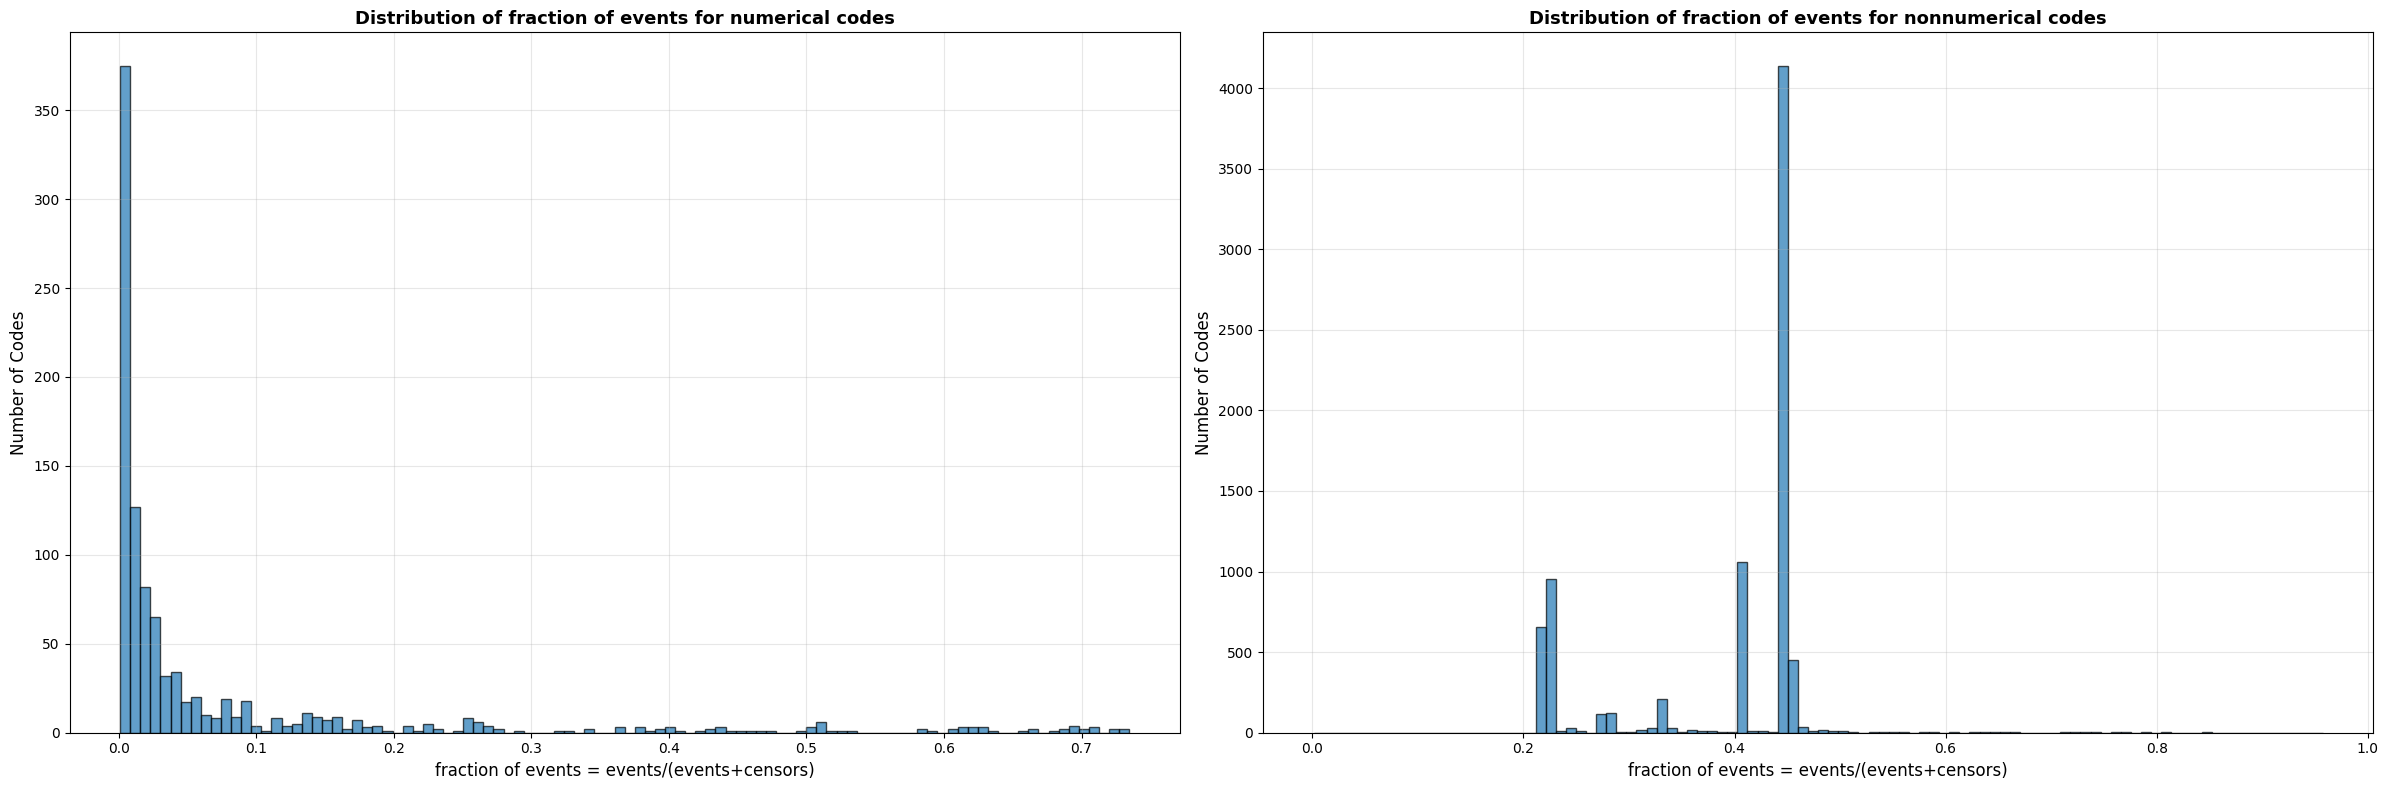

In [13]:
# 7175280
import matplotlib.pyplot as plt
non_numerical_ratio = []
numerical_ratio = []
numerical_codes = list(mtpp_task.numerical_task_to_index_map.keys())
print(numerical_codes)
for i in mtpp_task.pretraining_task_info:
    if i[0] in numerical_codes:
        numerical_ratio.append((i[3]/(i[2]+i[3])))
    else:
        non_numerical_ratio.append((i[3]/(i[2]+i[3])))
    # print(i[0],i[3]/(i[2]+i[3]),i[2]+i[3])

fig, axes = plt.subplots(1, 2, figsize=(24, 8))

# Plot 1: Distribution of non-missingness ratios
axes[0].hist(numerical_ratio, bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('fraction of events = events/(events+censors)', fontsize=12)
axes[0].set_ylabel('Number of Codes', fontsize=12)
axes[0].set_title('Distribution of fraction of events for numerical codes', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Distribution of code frequencies

axes[1].hist(non_numerical_ratio, bins=100, edgecolor='black', alpha=0.7)
axes[1].set_xlabel('fraction of events = events/(events+censors)', fontsize=12)
axes[1].set_ylabel('Number of Codes', fontsize=12)
axes[1].set_title('Distribution of fraction of events for nonnumerical codes', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)


# Create histogram


plt.tight_layout()
plt.savefig('numeric_codes_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
import pickle
ontology_path = "/data2/processed_datasets/zj2398/femr/ontology.pkl"
tokenizer_path = "/data2/processed_datasets/zj2398/femr/cumc_0.1/mtpp/tokenizer"
task_path = "/data2/processed_datasets/zj2398/femr/cumc_0.1/mtpp/mtpp_task.pkl"
with open(ontology_path, 'rb') as f:
    ontology = pickle.load(f)
# with open(task_path, 'rb') as f:
#     task = pickle.load(f)
# tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
mtpp_32k_tokenizer_path= "/data2/processed_datasets/zj2398/femr/cumc_0.1/mtpp_vocab_32k/tokenizer"
mtpp_32k_tokenizer = HierarchicalTokenizer.from_pretrained(mtpp_32k_tokenizer_path, ontology=ontology)
print(len(mtpp_32k_tokenizer.dictionary["vocab"]))
code_list = []
for i in mtpp_32k_tokenizer.dictionary["vocab"]:
    if i['type'] == "code":
        code_list.append(i)
print(len(code_list))

/data/anaconda3/envs/motor_chao/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
import pickle
from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
ontology_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/models/femr/motor_large_no_visit_id/ontology.pkl"
tokenizer_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/models/femr/motor_large_no_visit_id/tokenizer"
with open(ontology_path, 'rb') as f:
    ontology = pickle.load(f)
motor_tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
code_list = []
for i in motor_tokenizer.dictionary["vocab"]:
    if i['type'] == "code":
        code_list.append(i["code_string"])
print(len(code_list),code_list)

7532 ['MEDS_BIRTH', 'CPT4/1002795', 'Gender/F', 'Gender/M', 'Visit/OP', 'SNOMED/71388002', 'PCORNet/Generic-NI', 'Race/Unknown', 'Visit/OMOP4822459', 'RxNorm/1151131', 'ATC/A', 'LOINC/786-4//UCUM/g/dL', 'LOINC/718-7//UCUM/g/dL', 'ATC/C', 'ATC/B', 'ATC/G', 'LOINC/8462-4//UCUM/mm[Hg]', 'LOINC/8480-6//UCUM/mm[Hg]', 'ATC/J', 'ATC/S', 'RxNorm/1151133', 'ATC/N', 'LOINC/787-2//UCUM/fL', 'LOINC/785-6//UCUM/pg', 'LOINC/788-0//UCUM/%', 'ATC/D', 'ATC/R', 'LOINC/6690-2//UCUM/10*9/L', 'ATC/M', 'LOINC/2345-7//UCUM/mg/dL', 'Ethnicity/Unknown', 'LOINC/2160-0//UCUM/mg/dL', 'LOINC/2951-2//UCUM/mmol/L', 'LOINC/2823-3//UCUM/mmol/L', 'LOINC/789-8//UCUM/10*12/L', 'SNOMED/404684003', 'LOINC/29463-7//UCUM/[oz_av]', 'LOINC/3094-0//UCUM/mg/dL', 'LOINC/8867-4//UCUM//min', 'LOINC/20570-8//UCUM/%', 'RxNorm/1151126', 'LOINC/2075-0//UCUM/mmol/L', 'LOINC/17861-6//UCUM/mg/dL', 'LOINC/706-2//UCUM/%', 'LOINC/8302-2//UCUM/[in_us]', 'LOINC/2028-9//UCUM/mmol/L', 'ATC/P', 'LOINC/8310-5//UCUM/[degF]', 'LOINC/63503-7', 'Visit

tokenizer vocab: 116k
numerical 3k ->719

for 3k numerical codes. both 10% and whole dataset.
(1) ratio of missingness  (2) nonmissing value count

after filtering 0.001 lLOINC: 1994 (715). Snowmed 2651 (4).  


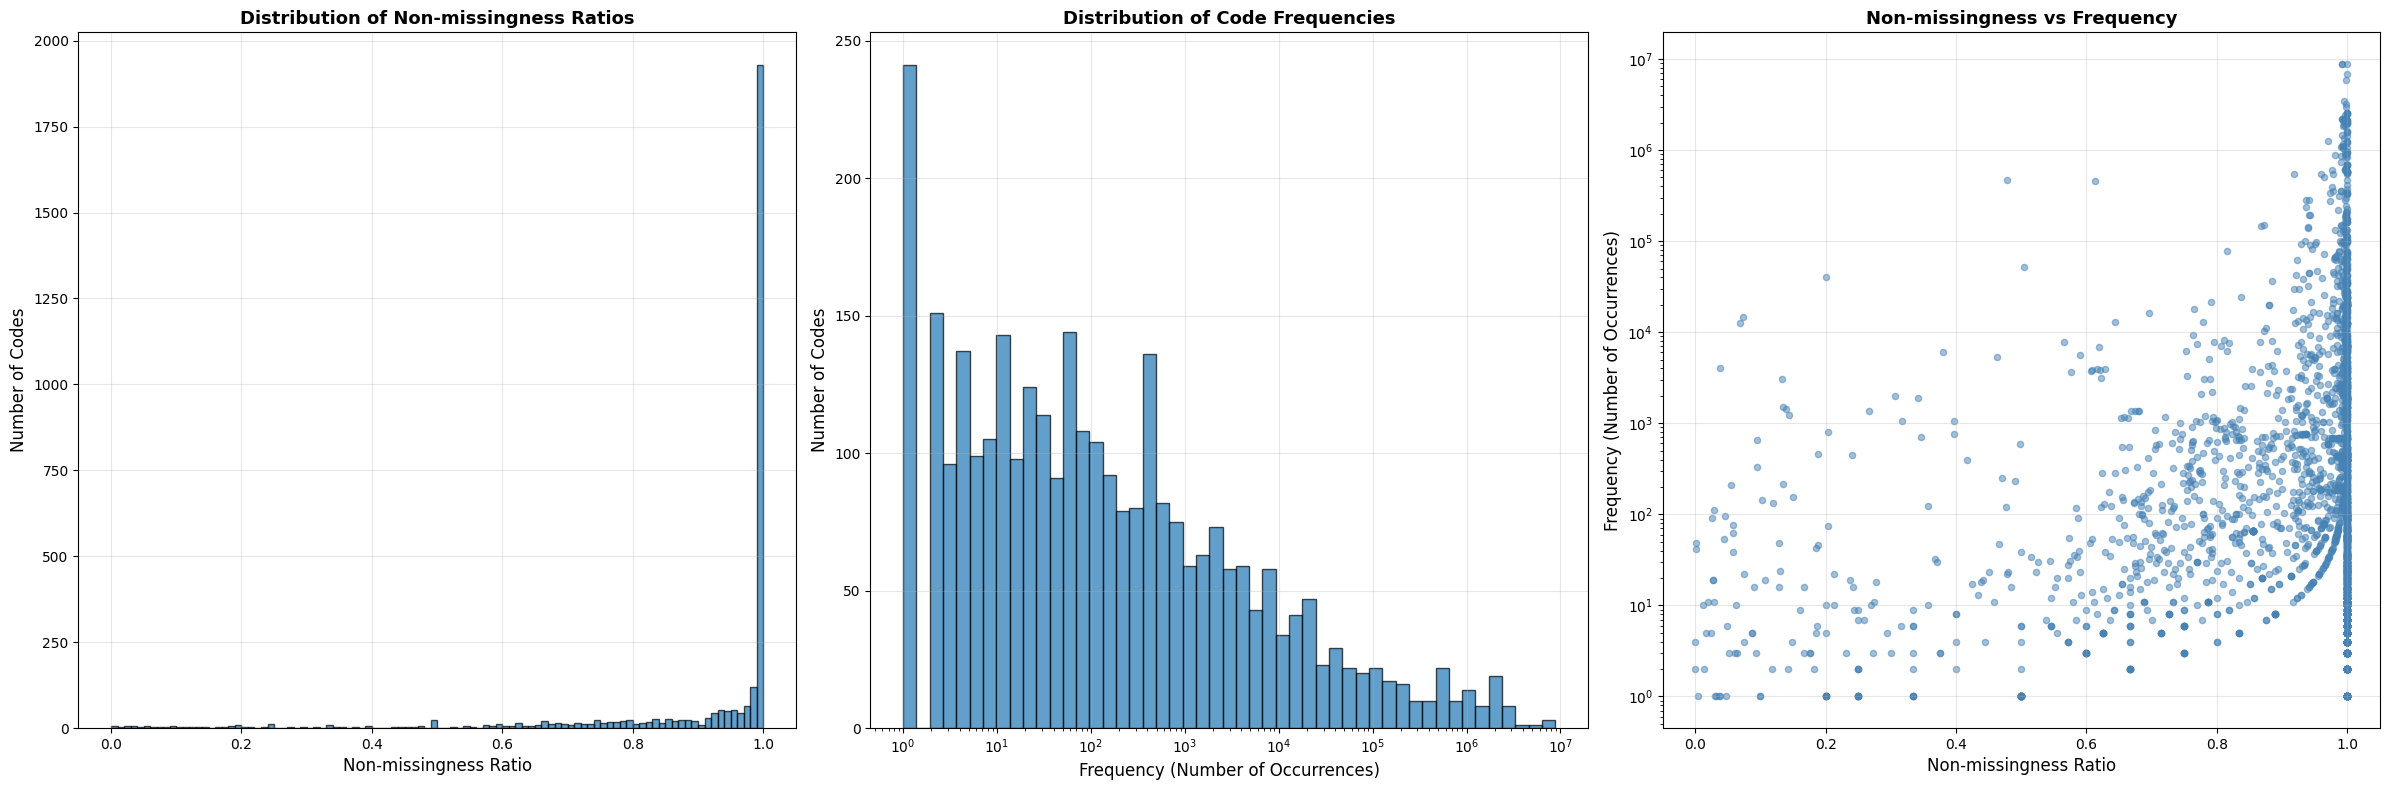

Total codes analyzed: 3090
Mean non-missingness ratio: 0.910
Median non-missingness ratio: 0.999
Mean frequency: 55625
Median frequency: 70


In [2]:
import meds_reader
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

meds_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader"
# numeric_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader/numeric_value"
database = meds_reader.SubjectDatabase(meds_path)
numeric_codes_set = set()

for subject_id in database:
    subject = database[subject_id]
    for event in subject.events:
        if event.numeric_value is not None:
            numeric_codes_set.add(event.code)

import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

# Collect statistics for all codes
code_stats = defaultdict(lambda: {'total': 0, 'numeric': 0})

for subject_id in database:
    subject = database[subject_id]
    for event in subject.events:
        code_stats[event.code]['total'] += 1
        # Check if numeric_value is actually a number (int or float)
        if event.numeric_value is not None and isinstance(event.numeric_value, (int, float)):
            code_stats[event.code]['numeric'] += 1
        elif event.numeric_value is not None and not isinstance(event.numeric_value, (int, float)):
            print(event.code,event.numeric_value)

# Filter to only numeric_codes_set and calculate metrics
nonmissingness_ratios = []
frequencies = []

for code in numeric_codes_set:
    if code in code_stats:
        total = code_stats[code]['total']
        numeric = code_stats[code]['numeric']
        ratio = numeric / total if total > 0 else 0
        
        nonmissingness_ratios.append(ratio)
        frequencies.append(numeric)

# Create the three plots
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

# Plot 1: Distribution of non-missingness ratios
axes[0].hist(nonmissingness_ratios, bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Non-missingness Ratio', fontsize=12)
axes[0].set_ylabel('Number of Codes', fontsize=12)
axes[0].set_title('Distribution of Non-missingness Ratios', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Distribution of code frequencies

# Use logarithmically spaced bins
bins = np.logspace(np.log10(min(frequencies)), np.log10(max(frequencies)), 50)

# Create histogram
axes[1].hist(frequencies, bins=bins, edgecolor='black', alpha=0.7)
# Set both axes to log scale
axes[1].set_xscale('log')
axes[1].set_xlabel('Frequency (Number of Occurrences)', fontsize=12)
axes[1].set_ylabel('Number of Codes', fontsize=12)
axes[1].set_title('Distribution of Code Frequencies', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)
# plt.yscale('log')

# Plot 3: 2D scatter plot
axes[2].scatter(nonmissingness_ratios, frequencies, alpha=0.5, s=20, c='steelblue')
axes[2].set_xlabel('Non-missingness Ratio', fontsize=12)
axes[2].set_ylabel('Frequency (Number of Occurrences)', fontsize=12)
axes[2].set_title('Non-missingness vs Frequency', fontsize=13, fontweight='bold')
axes[2].set_yscale('log')  # Log scale for better visualization
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('numeric_codes_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print(f"Total codes analyzed: {len(numeric_codes_set)}")
print(f"Mean non-missingness ratio: {np.mean(nonmissingness_ratios):.3f}")
print(f"Median non-missingness ratio: {np.median(nonmissingness_ratios):.3f}")
print(f"Mean frequency: {np.mean(frequencies):.0f}")
print(f"Median frequency: {np.median(frequencies):.0f}")

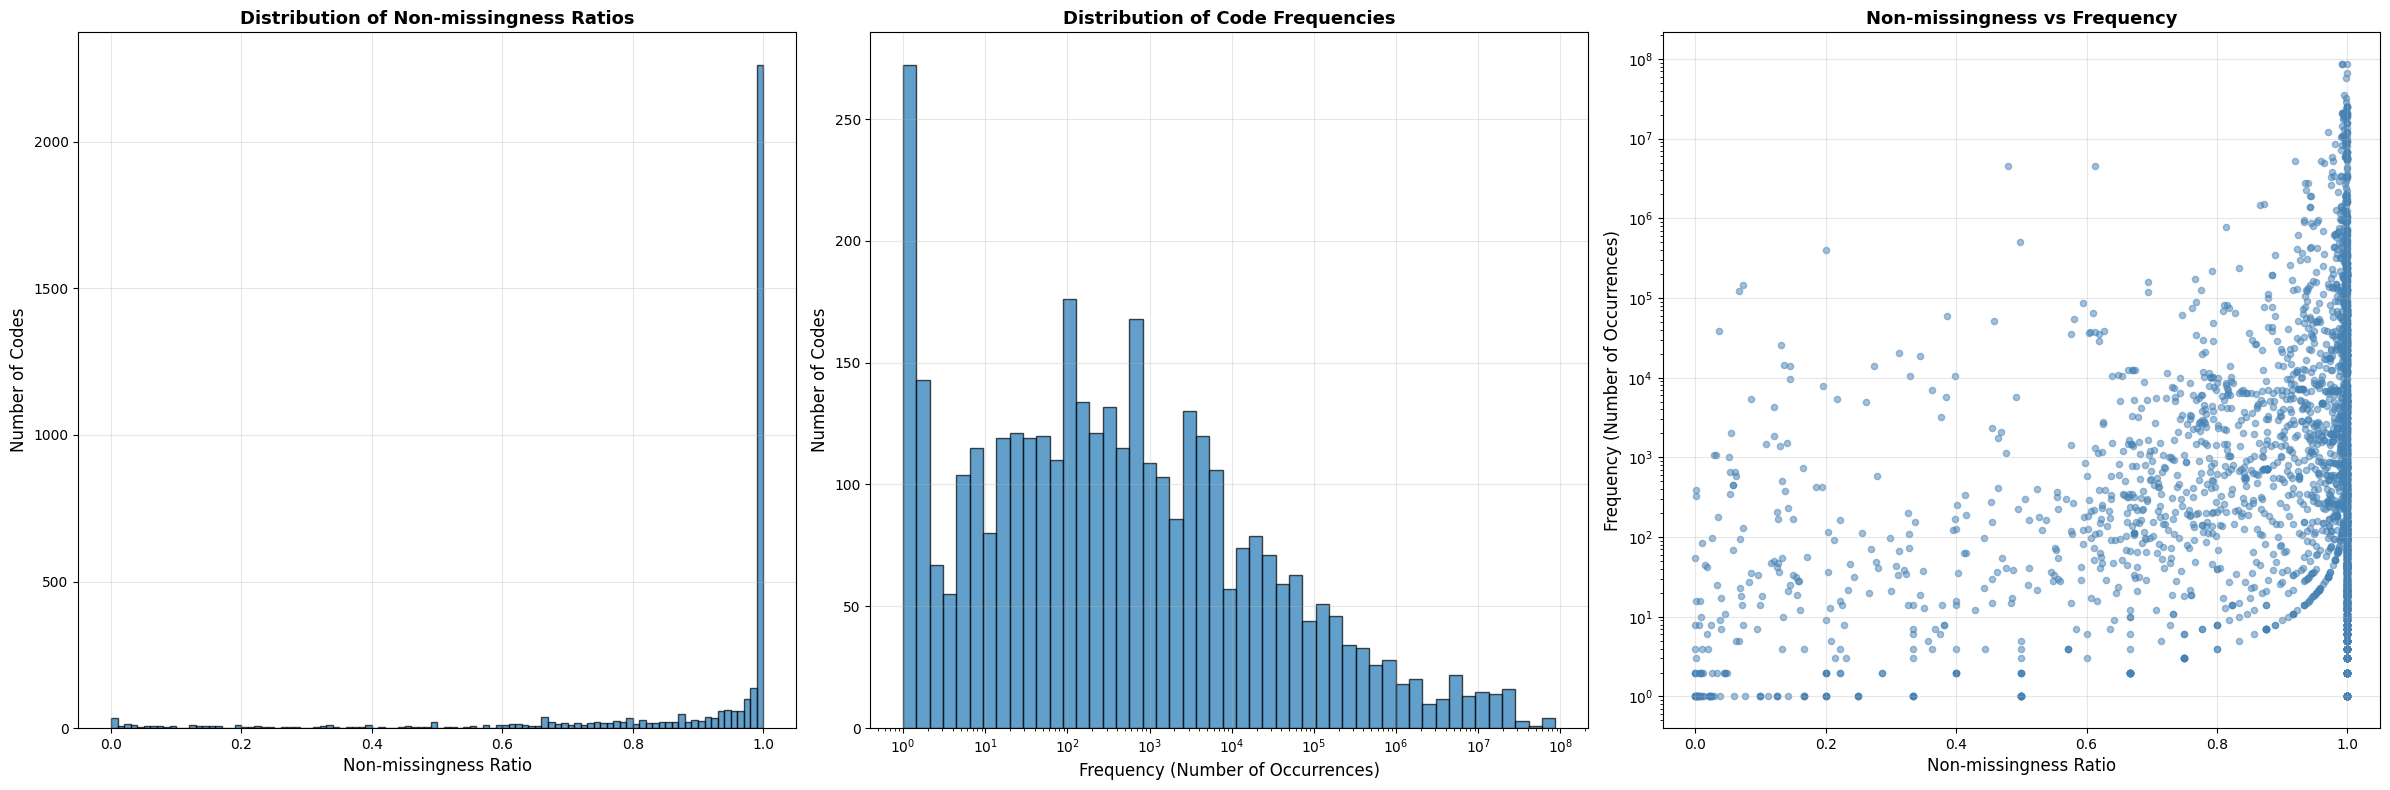

Total codes analyzed: 3738
Mean non-missingness ratio: 0.892
Median non-missingness ratio: 0.998
Mean frequency: 450204
Median frequency: 284


In [3]:
import meds_reader
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

meds_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_meds_reader"
# numeric_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader/numeric_value"
database = meds_reader.SubjectDatabase(meds_path)
numeric_codes_set = set()

for subject_id in database:
    subject = database[subject_id]
    for event in subject.events:
        if event.numeric_value is not None:
            numeric_codes_set.add(event.code)

import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

# Collect statistics for all codes
code_stats = defaultdict(lambda: {'total': 0, 'numeric': 0})

for subject_id in database:
    subject = database[subject_id]
    for event in subject.events:
        code_stats[event.code]['total'] += 1
        # Check if numeric_value is actually a number (int or float)
        if event.numeric_value is not None and isinstance(event.numeric_value, (int, float)):
            code_stats[event.code]['numeric'] += 1
        elif event.numeric_value is not None and not isinstance(event.numeric_value, (int, float)):
            print(event.code,event.numeric_value)

# Filter to only numeric_codes_set and calculate metrics
nonmissingness_ratios = []
frequencies = []

for code in numeric_codes_set:
    if code in code_stats:
        total = code_stats[code]['total']
        numeric = code_stats[code]['numeric']
        ratio = numeric / total if total > 0 else 0
        
        nonmissingness_ratios.append(ratio)
        frequencies.append(numeric)

# Create the three plots
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

# Plot 1: Distribution of non-missingness ratios
axes[0].hist(nonmissingness_ratios, bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Non-missingness Ratio', fontsize=12)
axes[0].set_ylabel('Number of Codes', fontsize=12)
axes[0].set_title('Distribution of Non-missingness Ratios', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Distribution of code frequencies

# Use logarithmically spaced bins
bins = np.logspace(np.log10(min(frequencies)), np.log10(max(frequencies)), 50)

# Create histogram
axes[1].hist(frequencies, bins=bins, edgecolor='black', alpha=0.7)
# Set both axes to log scale
axes[1].set_xscale('log')
axes[1].set_xlabel('Frequency (Number of Occurrences)', fontsize=12)
axes[1].set_ylabel('Number of Codes', fontsize=12)
axes[1].set_title('Distribution of Code Frequencies', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)
# plt.yscale('log')

# Plot 3: 2D scatter plot
axes[2].scatter(nonmissingness_ratios, frequencies, alpha=0.5, s=20, c='steelblue')
axes[2].set_xlabel('Non-missingness Ratio', fontsize=12)
axes[2].set_ylabel('Frequency (Number of Occurrences)', fontsize=12)
axes[2].set_title('Non-missingness vs Frequency', fontsize=13, fontweight='bold')
axes[2].set_yscale('log')  # Log scale for better visualization
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('numeric_codes_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print(f"Total codes analyzed: {len(numeric_codes_set)}")
print(f"Mean non-missingness ratio: {np.mean(nonmissingness_ratios):.3f}")
print(f"Median non-missingness ratio: {np.median(nonmissingness_ratios):.3f}")
print(f"Mean frequency: {np.mean(frequencies):.0f}")
print(f"Median frequency: {np.median(frequencies):.0f}")

In [44]:
print(len(code_stats))
print(len(numeric_codes_set))

# print(list(code_stats.keys())[:10])
# print(code_stats['ICD10CM/R07.90'])

# count = 0
code_list = []
for code_name,value in code_stats.items():
    ratio = value['numeric']/value['total']
    if 100000>value['numeric']>100:
        code_list.append(code_name)
print(len(code_list))

# for code in numeric_codes_set:
#         total = code_stats[code]['total']
#         numeric = code_stats[code]['numeric']
#         ratio = numeric / total if total > 0 else 0
        
#         nonmissingness_ratios.append(ratio)
#         frequencies.append(numeric)

# for code in numeric_codes_set:
#     if code in code_stats:
#         total = code_stats[code]['total']
#         numeric = code_stats[code]['numeric']
#         ratio = numeric / total if total > 0 else 0
        
#         nonmissingness_ratios.append(ratio)
#         frequencies.append(numeric)


83541
3090
1270


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import meds_reader
from collections import defaultdict

from collections import defaultdict
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor
import multiprocessing as mp

def count_codes_for_subjects(args):
    """Process a chunk of subjects and return local code counts"""
    subject_ids_chunk, meds_path = args
    database = meds_reader.SubjectDatabase(meds_path)
    local_stats = defaultdict(int)
    
    for subject_id in subject_ids_chunk:
        subject_num = database[subject_id]
        for event in subject_num.events:
            if (event.numeric_value is not None and 
                isinstance(event.numeric_value, (int, float)) and 
                event.text_value is None):
                local_stats[event.code] += 1
    
    return dict(local_stats)

def calculate_numeric_distribution(meds_path, n_workers=32):    
    # Split subject IDs into chunks
    database = meds_reader.SubjectDatabase(meds_path)
    subject_ids = list(database)
    chunk_size = max(1, len(subject_ids) // n_workers)
    chunks = [subject_ids[i:i + chunk_size] 
              for i in range(0, len(subject_ids), chunk_size)]
    
    # Prepare arguments for each worker
    args_list = [(chunk, meds_path) for chunk in chunks]
    
    # Process chunks in parallel (use ThreadPoolExecutor if database isn't picklable)
    code_stats = defaultdict(int)
    
    # Try ProcessPoolExecutor first (faster for CPU-bound), fallback to ThreadPoolExecutor
    # try:
    with ProcessPoolExecutor(max_workers=n_workers) as executor:
        results = executor.map(count_codes_for_subjects, args_list)
        # results = 
        
        # Merge results
        for local_stats in results:
            for code, count in local_stats.items():
                code_stats[code] += count
    
    # Filter: keep only codes with 100 <= count <= 10^6
    filtered_stats = {code: count for code, count in code_stats.items() 
                      if 400 <= count}
    
    # Sort by frequency (count) in descending order and return only keys
    sorted_codes = [(code,count) for code, count in 
                    sorted(filtered_stats.items(), key=lambda x: x[1], reverse=True)]
    
    # return sorted_codes
    return sorted_codes

# Usage

# def plot_numeric_distribution(database):
#     # Collect statistics for all codes
#     code_stats = defaultdict(lambda: {'total': 0, 'text':0,'numeric': 0,'both':0})

#     for subject_id in database:
#         subject = database[subject_id]
#         for event in subject.events:
#             code_stats[event.code]['total'] += 1
#             # Check if numeric_value is actually a number (int or float)
#             if event.numeric_value is not None and isinstance(event.numeric_value, (int, float)) and event.text_value is None:
#                 code_stats[event.code]['numeric'] += 1
#             elif event.numeric_value is not None and isinstance(event.numeric_value, (int, float)) and event.text_value is not None:
#                 code_stats[event.code]['both'] += 1
#             elif event.numeric_value is  None and event.text_value is not None:
#                 code_stats[event.code]['text'] += 1
#             elif event.numeric_value is not None and not isinstance(event.numeric_value, (int, float)):
#                 print(event.code,event.numeric_value)


#     return code_stats

meds_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_0.1_reader"
result_codes = calculate_numeric_distribution(meds_path, n_workers=32)
print(f"Found {len(result_codes)} codes meeting criteria")
print(result_codes)
# updated_code_stats = plot_numeric_distribution(database)

# 100 - 10000 1053
# 100 - 100000  1279
# 100 - 1000000  1356

Found 1035 codes meeting criteria
[('LOINC/8867-4//UCUM//min', 8816893), ('LOINC/8480-6//UCUM/mm[Hg]', 8761007), ('LOINC/8462-4//UCUM/mm[Hg]', 8756470), ('LOINC/9279-1//UCUM//min', 6837459), ('LOINC/8310-5//UCUM/[degF]', 5932040), ('LOINC/2708-6//UCUM/%', 3484810), ('LOINC/59408-5//UCUM/%', 3201156), ('LOINC/29463-7//UCUM/[oz_av]', 2975739), ('LOINC/60809-1//UCUM/mm[Hg]', 2564645), ('LOINC/8889-8//UCUM/%', 2535955), ('LOINC/76282-3//SNOMED/258983007', 2523786), ('LOINC/89278-6//SNOMED/258983007', 2492105), ('LOINC/60924-8//UCUM/mm[Hg]', 2472487), ('LOINC/718-7//UCUM/g/dL', 2427450), ('LOINC/2951-2//UCUM/mmol/L', 2190569), ('LOINC/2345-7//UCUM/mg/dL', 2178664), ('LOINC/2160-0//UCUM/mg/dL', 2177379), ('LOINC/786-4//UCUM/g/dL', 2172065), ('LOINC/2823-3//UCUM/mmol/L', 2171947), ('LOINC/20102-0//UCUM/cm[H2O]', 2122678), ('LOINC/56869-1//UCUM/mm', 2111797), ('LOINC/3094-0//UCUM/mg/dL', 2066256), ('LOINC/76171-8//SNOMED/258983007', 2059749), ('LOINC/76248-4//UCUM/cm[H2O]', 2027399), ('LOINC/7

In [7]:
from femr.models.tokenizer.hierarchical_tokenizer import HierarchicalTokenizer
import pickle
from collections import Counter
from pathlib import Path
ontology_path = "/data2/processed_datasets/zj2398/femr/ontology.pkl"
full_tokenizer_path = "/data/models/zj2398/femr/cumc_full/tpp/tokenizer"

subset_tokenizer_path_zilin = "/data2/processed_datasets/zj2398/femr/cumc_0.1/motor/tokenizer"
subset_ontology_path_zilin = "/data2/processed_datasets/zj2398/femr/cumc_0.1/motor/ontology.pkl"

subset_tokenizer_path_chao = "/data2/processed_datasets/zj2398/femr/cumc_0.1/motor_chao_ontology/tokenizer"
subset_ontology_path_chao = "/data2/processed_datasets/zj2398/femr/cumc_0.1/motor_chao_ontology/ontology.pkl"

full_path_chao = Path("/data2/processed_datasets/zj2398/femr/cumc/motor_chao")

# for tokenizer_path in [subset_token_path,full_token_path]:

def count_type(tokenizer_path,ontology_path):
    with open(ontology_path, 'rb') as f:
        ontology = pickle.load(f)
    vocab_type = Counter()
    tokenizer = HierarchicalTokenizer.from_pretrained(tokenizer_path, ontology=ontology)
    print(tokenizer.dictionary["vocab"][:10])
    for dict_entry in tokenizer.dictionary["vocab"]:
        if dict_entry["type"] == "code":
            code_type = dict_entry["code_string"].split("/")[0]
            vocab_type[code_type] += 1
    # print(vocab_type)
    return vocab_type

zilin_count = count_type(subset_tokenizer_path_zilin,subset_ontology_path_zilin)
chao_count = count_type(subset_tokenizer_path_chao,subset_ontology_path_chao)
chao_full_count = count_type(full_path_chao/"tokenizer",full_path_chao/"ontology.pkl")
print(zilin_count)
print(chao_count)
print(chao_full_count)

[{'type': 'numeric', 'property': 'numeric_value', 'val_start': -inf, 'val_end': -0.4000000059604645, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': -0.4000000059604645, 'val_end': 0.0, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.0, 'val_end': 0.009999999776482582, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.009999999776482582, 'val_end': 0.02388400018960239, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.02388400018960239, 'val_end': 0.029999999329447746, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.029999999329447746, 'val_end': 0.03999999910593033, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.03999999910593033, 'val_end': 0.05000000074505806, 'weight': -1}, {'type': 'numeric', 'property': 'numeric_value', 'val_start': 0.05000000074505806, 'val_end': 0.07000000029802322, 'weight': -1}, {'

In [21]:
concept_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3/CONCEPT.csv"

concept = pd.read_csv(
    concept_path,
    sep="\t",  # change to "\t" if your concept file is TSV
    usecols=["concept_id", "vocabulary_id", "concept_code"],
    dtype={"concept_id": "int64", "vocabulary_id": "string", "concept_code": "string"},
)
concept["code"] = concept["vocabulary_id"].astype("string") + "/" + concept["concept_code"].astype("string")
id_to_code = pd.Series(concept["code"].values, index=concept["concept_id"].values)

CHUNKSIZE = 2000000  # tune based on RAM (e.g., 500k, 1M, 2M)


usecols = ["ancestor_concept_id", "descendant_concept_id",
           "min_levels_of_separation", "max_levels_of_separation"]

# concept_relation_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3/CONCEPT_ANCESTOR.csv"
concept_relation = pd.read_csv(concept_relation_path,sep="\t",usecols=usecols,
    dtype={
        "ancestor_concept_id": "int64",
        "descendant_concept_id": "int64",
        "min_levels_of_separation": "int16",
        "max_levels_of_separation": "int16",
    },
    chunksize=CHUNKSIZE,
    )

# reader = pd.read_csv(
#     ancestor_path,
#     sep=ANC_SEP,
#     usecols=usecols,
#     dtype={
#         "ancestor_concept_id": "int64",
#         "descendant_concept_id": "int64",
#         "min_levels_of_separation": "int16",
#         "max_levels_of_separation": "int16",
#     },
#     chunksize=CHUNKSIZE,
# )

out_path = "/data2/processed_datasets/zj2398/femr/ancestor_mapping.csv"
first = True
for chunk in concept_relation:
    # Map IDs -> codes
    anc_code = chunk["ancestor_concept_id"].map(id_to_code)
    des_code = chunk["descendant_concept_id"].map(id_to_code)

    # If any IDs are missing in concept.csv, decide what to do:
    # Option A (recommended): keep original id as string when missing
    chunk["ancestor_concept_id"] = anc_code.fillna(chunk["ancestor_concept_id"].astype("string"))
    chunk["descendant_concept_id"] = des_code.fillna(chunk["descendant_concept_id"].astype("string"))

    # Write incrementally (TSV is typical for large files)
    chunk.to_csv(
        out_path,
        sep="\t",
        index=False,
        mode="w" if first else "a",
        header=first,
    )
    first = False


In [ ]:
from pathlib import Path
import pandas as pd
def check_parquet(base,motor,llama,cehrgpt):
    motor_scz_path = base / motor
    llama_scz_path = base / llama
    cehrgpt_scz_path = base / cehrgpt
    motor_scz = pd.read_parquet(motor_scz_path)
    llama_scz = pd.read_parquet(llama_scz_path)
    cehrgpt_scz  = pd.read_parquet(cehrgpt_scz_path)
    print(len(motor_scz))
    print(len(llama_scz))
    print(len(cehrgpt_scz))

finetune_base = Path("/data/results/foundation_benchmarking/CUMC/fine_tune/Schizophrenia")
check_parquet(finetune_base,"motor_53494.parquet","llama_53494.parquet","cehrgpt_53494.parquet")

prob_base = Path("/data/results/foundation_benchmarking/CUMC/log_prob/Schizophrenia")
check_parquet(prob_base,"motor_52419.parquet","llama_53222.parquet","cehrgpt_53494.parquet")

# check_parquet(prob_base,"motor_100.parquet","llama_100.parquet","cehrgpt_100.parquet")
# 
# for task in ["AMI","CLL","HTN","long_los"]:
#     prob_base = Path(f"/data/results/foundation_benchmarking/CUMC/log_prob/{task}")
#     check_parquet(prob_base,"motor_100000.parquet","llama_100000.parquet","cehrgpt_100000.parquet")
# print(cehrgpt_scz)

# motor_prediction = pd.read_parquet("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/models/femr/motor_large_no_visit_id/results/Schizophrenia/motor_730/test_predictions/predictions.parquet")
# print(motor_prediction)

# llama_finetune = pd.read_parquet("/data/results/foundation_benchmarking/CUMC/fine_tune/Schizophrenia/llama_53494.parquet")
# llama_finetune = pd.read_parquet("/data/results/zj2398/fomoh/cumc/finetuning/llama_code_8k_float32/finetune_grid_search_Schizophrenia_warmup_0.1/inference/llama_100000.parquet")

# llama_prob = pd.read_parquet("/data/results/foundation_benchmarking/CUMC/log_prob/Schizophrenia/llama_53222.parquet")
# print(len(llama_finetune["subject_id"].unique()))
# print(len(llama_prob["subject_id"].unique()))
# print(llama_finetune)
# print(llama_prob)

# sublist = list(llama_finetune["subject_id"].unique())
# llama_prob_subsample = llama_prob[llama_prob['subject_id'].isin(sublist)]
# print(len(llama_prob_subsample))

23214
23040
23214
22527
23093
23214
1065


In [6]:
scz_test = pd.read_parquet("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/task_labels/phenotype_sample/Schizophrenia/held_out.parquet")
print(scz_test)

scz_llama = pd.read_parquet("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/llama_code_8k_float32/Schizophrenia/features_with_label/test.parquet")
scz_mamba = pd.read_parquet("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/mamba_code_8k_float32/Schizophrenia/features_with_label/test.parquet")
scz_motor = pd.read_parquet("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/models/femr/motor_large_no_visit_id/results/Schizophrenia/motor/test_predictions/predictions.parquet")
print(scz_llama)
print(scz_mamba)
print(scz_motor)

       subject_id prediction_time  boolean_value     split
0        10822775      1989-07-22              1  held_out
1        10822775      1990-03-21              1  held_out
2        10822775      1990-04-07              1  held_out
3        10822775      1989-12-30              1  held_out
20        3695820      1989-06-05              1  held_out
...           ...             ...            ...       ...
76690     9493294      1996-11-21              0  held_out
76691     9493294      1996-11-07              0  held_out
76692     9493294      1990-02-19              0  held_out
76693     9493294      1996-12-05              0  held_out
76694     9493294      1990-05-31              0  held_out

[23214 rows x 4 columns]
       subject_id prediction_time  boolean_value  \
0           16694      2021-12-15              0   
1           16694      2022-01-08              0   
2           16694      2022-01-09              0   
3           16694      2022-04-12              0   
4     

In [17]:
import pandas as pd
from pathlib import Path
# for task in ["ami","masld","stroke","in_hospital_mortality","readmission","long_los"]:
#     few_shot = 100000
#     motor_df = pd.read_parquet(f"/data/results/foundation_benchmarking/MIMIC/log_prob/{task}/motor_{few_shot}.parquet")
#     cehrgpt_df = pd.read_parquet(f"/data/results/foundation_benchmarking/MIMIC/log_prob/{task}/cehrgpt_{few_shot}.parquet")
#     llama_df = pd.read_parquet(f"/data/results/foundation_benchmarking/MIMIC/log_prob/{task}/llama_{few_shot}.parquet")
#     print(len(motor_df)==len(cehrgpt_df)==len(llama_df))

few_shot = 100
base_dir = Path("/data/results/foundation_benchmarking/CUMC/log_prob")
for subdir in base_dir.iterdir():
    if subdir.is_dir():
        motor_df = pd.read_parquet(subdir/f"motor_{few_shot}.parquet")
        cehrgpt_df = pd.read_parquet(subdir/f"cehrgpt_{few_shot}.parquet")
        llama_df = pd.read_parquet(subdir/f"llama_{few_shot}.parquet")
        print(subdir.name,len(motor_df),len(cehrgpt_df),len(llama_df))
# print(cehrgpt_df)

death 50000 50000 50000
Ischemic_Stroke 50000 50000 50000
MASLD 50000 50000 50000
T2DM 50000 50000 50000
readmission 50000 50000 50000
Osteoporosis 50000 50000 50000
Pancreatic_Cancer 50000 50000 50000
AMI 50000 50000 50000
SLE 50000 50000 50000
long_los 50000 50000 50000
Celiac 50000 50000 50000
HTN 50000 50000 50000
CLL 50000 50000 50000
Schizophrenia 22527 23214 23093


In [ ]:
# for task in ["AMI","CLL","HTN","long_los"]:
#     prob_base = Path(f"/data/results/foundation_benchmarking/CUMC/log_prob/{task}")
#     check_parquet(prob_base,"motor_100000.parquet","llama_100000.parquet","cehrgpt_100000.parquet")


50000
50000
50000
50000
50000
50000
50000
50000
50000
50000
50000
50000


In [ ]:
import meds_reader
import numpy as np
import pandas as pd
import pickle
from datetime import timedelta

cumc = meds_reader.SubjectDatabase("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/post_transform_meds_reader")
main_split = pd.read_csv("/data2/processed_datasets/zj2398/femr/cumc/main_split.csv")
cumc_train_id = list(main_split[main_split["split_name"]=="train"]['subject_id'])
cumc_test_id = list(main_split[main_split["split_name"]=="test"]['subject_id'])
print(len(cumc_train_id))
print(len(cumc_test_id))

patient_list=[np.int64(14802052), np.int64(8086021), np.int64(4023685), np.int64(15573266), np.int64(3020189), np.int64(3068067), np.int64(10744356), np.int64(4751140), np.int64(7026734), np.int64(8430128), np.int64(13342130), np.int64(12090419), np.int64(14396980), np.int64(2228544), np.int64(1625794), np.int64(6409808), np.int64(2475735), np.int64(1170523), np.int64(10184927), np.int64(7267807), np.int64(12305631)]
motor_list = [np.int64(13175680), np.int64(1604356), np.int64(8086021), np.int64(14250374), np.int64(4023685), np.int64(14802052), np.int64(6322825), np.int64(13670543), np.int64(2524305), np.int64(15573266), np.int64(3932563), np.int64(6524572), np.int64(13303837), np.int64(3020189), np.int64(7949473), np.int64(477218), np.int64(3068067), np.int64(10744356), np.int64(14286497), np.int64(4751140), np.int64(12985895), np.int64(4101416), np.int64(8085932), np.int64(1243565), np.int64(7026734), np.int64(8430128), np.int64(13342130), np.int64(12090419), np.int64(14396980), np.int64(3887159), np.int64(6067895), np.int64(5735740), np.int64(8220477), np.int64(2228544), np.int64(1625794), np.int64(4844611), np.int64(5916484), np.int64(7554245), np.int64(7007300), np.int64(11840838), np.int64(8950220), np.int64(798797), np.int64(9626446), np.int64(12535116), np.int64(1957197), np.int64(9720273), np.int64(4529743), np.int64(6409808), np.int64(2475735), np.int64(6612442), np.int64(1170523), np.int64(8809820), np.int64(14568956), np.int64(5490014), np.int64(12305631), np.int64(7267807), np.int64(10184927), np.int64(15236704), np.int64(9086697), np.int64(2888430), np.int64(5062510), np.int64(1636850), np.int64(4733810), np.int64(11939570), np.int64(13390460)]
motor_difference_llama = [i for i in motor_list if i not in patient_list]

print(len(motor_difference_llama),len(motor_list),len(patient_list))

# scz_test = pd.read_parquet("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/task_labels/phenotype_sample/Schizophrenia/held_out.parquet")
# print(scz_test)
# print(len(scz_test["subject_id"].unique()))
scz_motor_features_path = "/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/models/femr/motor_large_no_visit_id/features/Schizophrenia_motor_730.pkl"
with open (scz_motor_features_path,"rb") as file:
    scz_motor_features = pickle.load(file)

features_test_id = [i for i in set(scz_motor_features['subject_ids']) if i in cumc_test_id]
print(len(features_test_id))

# for i in motor_difference_llama:
#     if i in scz_motor_features['subject_ids']:
#         print(i)

# for i in motor_list:
#     if i not in patient_list:
#         print(i,scz_test[scz_test["subject_id"]==i])
#         for event in cumc[i].events:
#             print(event)
#     break

# for row in exclude_df.itertuples(index=False):
#     subject_id = row.subject_id
#     prediction_time = row.prediction_time
#     all_events = cumc[subject_id].events
#     filtered_events = filtered_events = [(event.code,event.time) for event in all_events if prediction_time - timedelta(days=2*365) <= event.time <= prediction_time+timedelta(days=1)]
#     print(subject_id, len(all_events),prediction_time,filtered_events)

# print(prediction_time)
# for id in patient_list:
#     for event in cumc[8086021].events:
#         print(event)
#     break

4701857
2015082
44 65 21
1021


In [ ]:
patient_list=[np.int64(14802052), np.int64(8086021), np.int64(4023685), np.int64(15573266), np.int64(3020189), np.int64(3068067), np.int64(10744356), np.int64(4751140), np.int64(7026734), np.int64(8430128), np.int64(13342130), np.int64(12090419), np.int64(14396980), np.int64(2228544), np.int64(1625794), np.int64(6409808), np.int64(2475735), np.int64(1170523), np.int64(10184927), np.int64(7267807), np.int64(12305631)]
scz_test = pd.read_parquet("/data2/processed_datasets/ehr_foundation_data/ohdsi_cumc_deid/ohdsi_cumc_deid_2023q4r3_v3_mapped/task_labels/phenotype_sample/Schizophrenia/held_out.parquet")
exclude_df = scz_test[scz_test["subject_id"].isin(patient_list)]
print(exclude_df)
for row in exclude_df.itertuples(index=False):
    subject_id = row.subject_id
    prediction_time = row.prediction_time
    all_events = cumc[subject_id].events
    filtered_events = filtered_events = [(event.code,event.time) for event in all_events if prediction_time - timedelta(days=2*365) <= event.time <= prediction_time+timedelta(days=1)]
    print(subject_id, len(all_events),prediction_time,filtered_events)

21
4751140 104 1998-10-05 00:00:00 []
3068067 63 1993-03-31 00:00:00 []
3020189 58 1994-11-09 00:00:00 []
6409808 33 1995-09-29 00:00:00 []
1170523 101 2007-12-13 00:00:00 []
13342130 25 1998-05-26 00:00:00 []
12305631 56 1994-11-18 00:00:00 []
2228544 17 2012-08-11 00:00:00 []
8086021 115 1996-02-24 00:00:00 []
14396980 47 1997-08-30 00:00:00 []
4023685 283 1991-10-30 00:00:00 []
12090419 301 2018-05-10 00:00:00 []
8430128 183 2002-06-08 00:00:00 []
2475735 279 2016-06-03 00:00:00 []
10744356 180 1997-12-25 00:00:00 []
15573266 89 1997-03-20 00:00:00 []
14802052 57 1992-05-20 00:00:00 []
7267807 89 2001-03-17 00:00:00 []
1625794 351 2009-01-02 00:00:00 []
7026734 2329 2004-11-20 00:00:00 []
10184927 301 2014-11-10 00:00:00 []


In [16]:
from pathlib import Path
scz_label = scz_test[scz_test["subject_id"]==13175680].sort_values("prediction_time")
print(len(scz_label))
print(scz_label)

sub_dir = Path("/data/results/foundation_benchmarking/CUMC/log_prob/Schizophrenia")
motor_df = pd.read_parquet(sub_dir/f"llama_100.parquet")
prediction_df = motor_df[motor_df["subject_id"]==13175680].sort_values("prediction_time")
print(len(prediction_df))
print(prediction_df)
# print()

# few_shot = 100
# base_dir = Path("/data/results/foundation_benchmarking/CUMC/log_prob/")
# for subdir in base_dir.iterdir():
#     if subdir.is_dir():
#         motor_df = pd.read_parquet(subdir/f"motor_{few_shot}.parquet")
#         cehrgpt_df = pd.read_parquet(subdir/f"cehrgpt_{few_shot}.parquet")
#         llama_df = pd.read_parquet(subdir/f"llama_{few_shot}.parquet")
#         print(subdir.name,len(motor_df),len(cehrgpt_df),len(llama_df))

27
       subject_id prediction_time  boolean_value     split
38698    13175680      1995-05-18              0  held_out
38689    13175680      1996-07-05              0  held_out
38696    13175680      1996-07-18              0  held_out
38694    13175680      1996-07-25              0  held_out
38692    13175680      1996-07-27              0  held_out
38700    13175680      1996-08-01              0  held_out
38684    13175680      1996-08-08              0  held_out
38695    13175680      1999-02-28              0  held_out
38704    13175680      1999-03-01              0  held_out
38683    13175680      1999-03-05              0  held_out
38682    13175680      1999-03-14              0  held_out
38685    13175680      1999-04-04              0  held_out
38688    13175680      1999-04-18              0  held_out
38702    13175680      1999-06-03              0  held_out
38687    13175680      1999-06-09              0  held_out
38703    13175680      2000-01-15              0  hel

In [ ]:
print(len(scz_test["subject_id"].unique()))

for subject_id in motor_difference_llama:
    prediction_time = scz_test[scz_test['subject_id']==subject_id]["prediction_time"].min()
    all_events = cumc[subject_id].events
    filtered_events = filtered_events = [(event.code,event.time) for event in all_events if prediction_time - timedelta(days=2*365) <= event.time <= prediction_time]
    print(subject_id, len(all_events),prediction_time,filtered_events)
    

       subject_id prediction_time  boolean_value     split
0        10822775      1989-07-22              1  held_out
1        10822775      1990-03-21              1  held_out
2        10822775      1990-04-07              1  held_out
3        10822775      1989-12-30              1  held_out
20        3695820      1989-06-05              1  held_out
...           ...             ...            ...       ...
76690     9493294      1996-11-21              0  held_out
76691     9493294      1996-11-07              0  held_out
76692     9493294      1990-02-19              0  held_out
76693     9493294      1996-12-05              0  held_out
76694     9493294      1990-05-31              0  held_out

[23214 rows x 4 columns]
1086
13175680 425 1995-05-18 00:00:00 []
1604356 281 2017-09-10 00:00:00 []
14250374 2799 2014-03-11 00:00:00 []
6322825 105 2013-10-04 00:00:00 []
13670543 242 1996-08-07 00:00:00 []
2524305 1598 2014-12-02 00:00:00 []
3932563 528 2019-04-07 00:00:00 []
6524572 508

In [ ]:
import pandas as pd
llama_scz_train = pd.read_parquet("/data/results/zj2398/fomoh/cumc/linear_probing/llama_code_8k_float32/Schizophrenia/features_with_label/train.parquet")
llama_scz_test = pd.read_parquet("/data/results/zj2398/fomoh/cumc/linear_probing/llama_code_8k_float32/Schizophrenia/features_with_label/test.parquet")
print()
print(llama_scz_train)
print(llama_scz_test)

       subject_id prediction_time  boolean_value  \
0            3411      2016-07-17              1   
1            3411      2017-02-24              1   
2            3411      2017-05-13              1   
3            3411      2017-09-10              1   
4            3411      2017-10-22              1   
...           ...             ...            ...   
53217    15623575      2019-03-28              0   
53218    15623575      2021-06-25              0   
53219    15623575      2021-12-09              0   
53220    15623575      2022-11-16              0   
53221    15623575      2023-01-13              0   

                                                features  
0      [0.86328125, -0.279296875, 0.392578125, -1.484...  
1      [0.46484375, 0.65625, 0.54296875, -0.1953125, ...  
2      [-0.6796875, 2.046875, 0.3671875, 0.06640625, ...  
3      [1.703125, 1.1796875, 0.8984375, -1.2109375, 0...  
4      [-2.53125, 0.546875, 1.609375, -0.54296875, 0....  
...                  